# Milestone 1: Addressing a reinforcement learning problem

**Question:** Can the Okanogan task ("deliver an item to a target, never hit a shelf") be framed as RL, and what does an agent that acts at random achieve in a ready-made environment?

| RL element | Okanogan warehouse robot | Taxi-v3 (stand-in) |
|---|---|---|
| State | robot, item and target positions, holding flag, blocked neighbours | taxi position, passenger location, destination (500 states) |
| Actions | up, down, left, right | N, S, E, W, pickup, drop-off |
| Reward | -1 per step, bonus for delivery, penalty for bumping a shelf | -1 per step, +20 delivery, -10 illegal pickup/drop-off |
| Episode end | delivered or time limit | delivered or 200 steps |

Taxi is the same problem in miniature, so it is the first environment. Note: current Gymnasium ships this environment as `Taxi-v4` (same dynamics as the course's `Taxi-v3`).

In [1]:
import sys, json; sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, gymnasium as gym
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
def random_agent(env_id, episodes=10, seed=0, **kw):
    """Action-observation loop with a random agent; returns the reward at every time step of every episode."""
    env = gym.make(env_id, **kw); env.action_space.seed(seed); per_episode = []
    for ep in range(episodes):
        obs, info = env.reset(seed=seed + ep); rewards, done = [], False
        while not done:
            obs, r, terminated, truncated, info = env.step(env.action_space.sample())
            rewards.append(r); done = terminated or truncated
        per_episode.append(rewards)
    return env, per_episode

## Taxi: create the environment and inspect it

In [2]:
env = gym.make("Taxi-v4", render_mode="ansi")
print("observation space:", env.observation_space)
print("action space:     ", env.action_space)
obs, _ = env.reset(seed=0)
print("\nstart state", obs, "decodes to (taxi row, taxi col, passenger, destination):", tuple(env.unwrapped.decode(obs)))
print(env.render())

observation space: Discrete(500)
action space:      Discrete(6)

start state 314 decodes to (taxi row, taxi col, passenger, destination): (3, 0, 3, 2)
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+




### Render a chosen state and view its reward table

In [3]:
state = env.unwrapped.encode(3, 1, 2, 0)      # taxi at row 3 col 1, passenger at location 2, destination 0
env.unwrapped.s = state
print(env.render())
actions = ["south", "north", "east", "west", "pickup", "dropoff"]
print("Reward table for this state: action -> (probability, next state, reward, done)")
for a, outcomes in env.unwrapped.P[state].items(): print(f"  {actions[a]:8s}", outcomes[0])
nxt, r, term, trunc, info = env.step(1)
print("\nstep(north) ->", dict(next_state=nxt, reward=r, terminated=term, truncated=trunc, info=info))

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+


Reward table for this state: action -> (probability, next state, reward, done)
  south    (1.0, 428, -1, False)
  north    (1.0, 228, -1, False)
  east     (1.0, 348, -1, False)
  west     (1.0, 328, -1, False)
  pickup   (1.0, 328, -10, False)
  dropoff  (1.0, 328, -10, False)

step(north) -> {'next_state': 228, 'reward': -1, 'terminated': False, 'truncated': False, 'info': {'prob': 1.0, 'action_mask': array([1, 1, 1, 1, 0, 0], dtype=int8)}}


## Taxi: random agent, cumulative reward over one episode

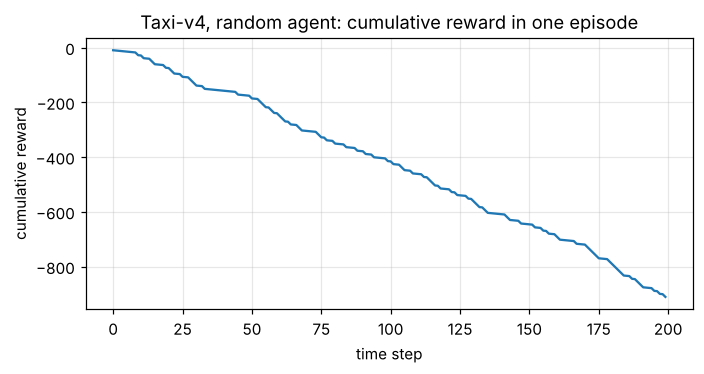

In [4]:
env, eps = random_agent("Taxi-v4", episodes=10)
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(np.cumsum(eps[0])); ax.set(title="Taxi-v4, random agent: cumulative reward in one episode", xlabel="time step", ylabel="cumulative reward")
plt.tight_layout(); plt.savefig("../docs/img/m1_taxi_one_episode.png"); plt.show()

## Taxi: random agent over 10 episodes, average performance over time

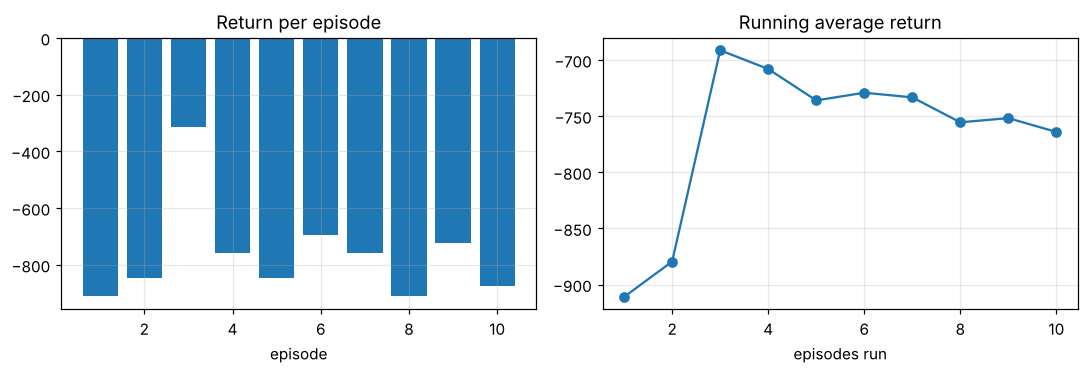

{'mean_return': -764.1, 'mean_length': 188.4}


In [5]:
returns = np.array([sum(e) for e in eps]); lengths = np.array([len(e) for e in eps])
avg = np.cumsum(returns) / np.arange(1, len(returns) + 1)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].bar(range(1, 11), returns); ax[0].set(title="Return per episode", xlabel="episode")
ax[1].plot(range(1, 11), avg, marker="o"); ax[1].set(title="Running average return", xlabel="episodes run")
plt.tight_layout(); plt.savefig("../docs/img/m1_taxi_ten_episodes.png"); plt.show()
taxi = dict(mean_return=float(returns.mean()), mean_length=float(lengths.mean()))
print(taxi)

## Repeat with a classic control environment: CartPole-v1

observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
action space:      Discrete(2)


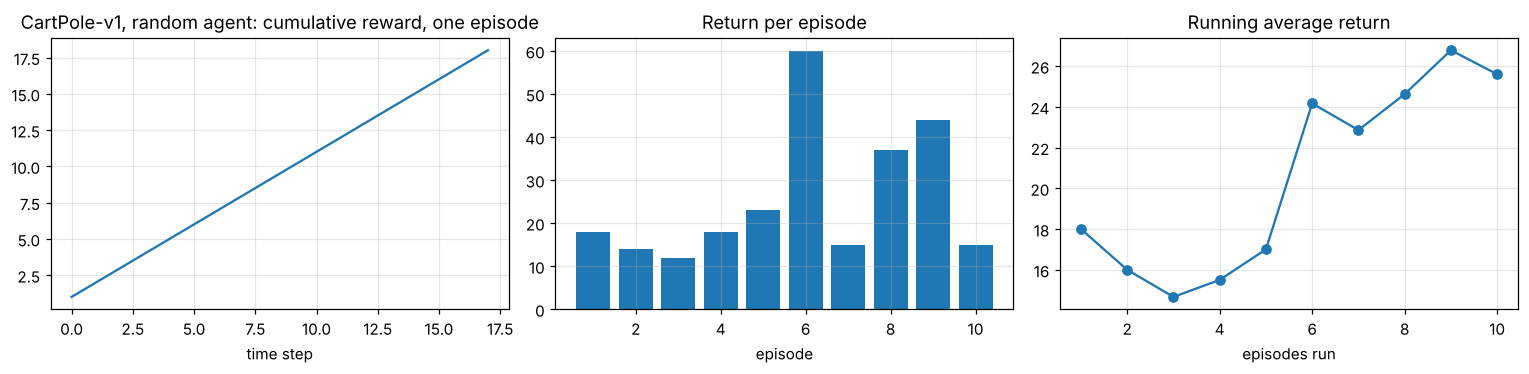

{'mean_return': 25.6}


In [6]:
env = gym.make("CartPole-v1")
print("observation space:", env.observation_space); print("action space:     ", env.action_space)
env, cp = random_agent("CartPole-v1", episodes=10)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].plot(np.cumsum(cp[0])); ax[0].set(title="CartPole-v1, random agent: cumulative reward, one episode", xlabel="time step")
cr = np.array([sum(e) for e in cp]); ax[1].bar(range(1, 11), cr); ax[1].set(title="Return per episode", xlabel="episode")
ax[2].plot(range(1, 11), np.cumsum(cr) / np.arange(1, 11), marker="o"); ax[2].set(title="Running average return", xlabel="episodes run")
plt.tight_layout(); plt.savefig("../docs/img/m1_cartpole.png"); plt.show()
cartpole = dict(mean_return=float(cr.mean()))
print(cartpole)
json.dump(dict(taxi=taxi, cartpole=cartpole), open("../results/m1_random_agents.json", "w"))

## Takeaways
- A random Taxi driver earns a mean return of **-764 over 10 episodes** and almost always runs into the 200-step limit (mean length 188), so it almost never delivers.
- Random CartPole balances for only **~26 steps** on average (mean return 25.6), because the pole falls quickly. The same random-agent loop works unchanged on any Gymnasium environment.
- The warehouse task maps onto the same state/action/reward structure, so the next step is to replace the random agent with a learning one.